# Baseline Models and Model Comparison

## Project: Traffic & Accident Risk Analytics

### Objective
Train and compare Logistic Regression, Random Forest, and Gradient Boosting models to predict crash severity among recorded Texas CRIS crashes.

### Research focus
- Class-aware model evaluation
- Year-based validation
- Prevention of target leakage
- Reliable comparison across crash severity classes

### Evaluation metrics
- Macro F1-score
- Balanced accuracy
- Per-class precision and recall
- Confusion matrix

## Step 1 — Clone your GitHub repository

In [ ]:
%cd /content

!git clone https://github.com/rishitha-2602/traffic-accident-risk-analytics.git traffic-project

/content
Cloning into 'traffic-project'...
remote: Enumerating objects: 169, done.
remote: Counting objects: 100% (70/70), done.
remote: Compressing objects: 100% (62/62), done.
remote: Total 169 (delta 19), reused 53 (delta 8), pack-reused 99 (from 1)
Receiving objects: 100% (169/169), 125.72 MiB | 16.58 MiB/s, done.
Resolving deltas: 100% (63/63), done.
Updating files: 100% (89/89), done.


## Step 2 — Verify the downloaded dataset

In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/traffic-project")

for name in [
    "data/processed/crash_cleaned.csv",
    "data/processed/feature_engineered.csv",
]:
    path = PROJECT_DIR / name

    print(f"\nFile: {name}")
    print("Exists:", path.exists())

    if path.exists():
        print("Size (MB):", round(path.stat().st_size / (1024 * 1024), 2))


File: data/processed/crash_cleaned.csv
Exists: True
Size (MB): 234.79

File: data/processed/feature_engineered.csv
Exists: True
Size (MB): 34.24


## Step 3 — Verify target mapping and year-wise class balance

In [ ]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path("/content/traffic-project")

raw_path = PROJECT_DIR / "data/processed/crash_cleaned.csv"
feature_path = PROJECT_DIR / "data/processed/feature_engineered.csv"

# Load only the raw columns needed for checking the target mapping
raw = pd.read_csv(
    raw_path,
    usecols=["Crash_ID", "Crash_Sev_ID"],
    low_memory=False
)

features = pd.read_csv(feature_path, low_memory=False)

# Compare the original severity codes with engineered target labels
check = features[["Crash_ID", "Severity_Target"]].merge(
    raw,
    on="Crash_ID",
    how="left",
    validate="one_to_one"
)

print("ORIGINAL SEVERITY CODE vs ENGINEERED TARGET")
display(pd.crosstab(
    check["Crash_Sev_ID"],
    check["Severity_Target"],
    margins=True,
    dropna=False
))

print("\nMISSING TARGET BY YEAR")
print(
    features.assign(
        Target_Missing=features["Severity_Target"].isna()
    )
    .groupby("Crash_Year")["Target_Missing"]
    .agg(["sum", "count"])
)

print("\nTARGET DISTRIBUTION BY YEAR")
display(pd.crosstab(
    features["Crash_Year"],
    features["Severity_Target"],
    margins=True,
    dropna=False
))

print("\nDUPLICATE CRASH IDs:", features["Crash_ID"].duplicated().sum())

ORIGINAL SEVERITY CODE vs ENGINEERED TARGET


Severity_Target,Fatal_Injury,Minor_Injury,Not_Injured,Possible_Injury,Serious_Injury,NaN,All
Crash_Sev_ID,,,,,,,
0,0,0,0,0,0,30180,30180
1,0,0,0,0,12322,0,12322
2,0,62226,0,0,0,0,62226
3,0,0,0,69741,0,0,69741
4,2565,0,0,0,0,0,2565
5,0,0,273456,0,0,0,273456
95,0,0,0,0,0,1,1
All,2565,62226,273456,69741,12322,0,450491



MISSING TARGET BY YEAR
             sum  count
Crash_Year             
2021        7562  97947
2022        7163  94700
2023        6666  92082
2024        4611  83092
2025        4179  82670

TARGET DISTRIBUTION BY YEAR


Severity_Target,Fatal_Injury,Minor_Injury,Not_Injured,Possible_Injury,Serious_Injury,NaN,All
Crash_Year,,,,,,,
2021,550,11396,59573,16235,2631,7562,97947
2022,533,12255,57449,14780,2520,7163,94700
2023,530,12761,55932,13769,2424,6666,92082
2024,502,12585,50156,12919,2319,4611,83092
2025,450,13229,50346,12038,2428,4179,82670
All,2565,62226,273456,69741,12322,0,450491



DUPLICATE CRASH IDs: 0


## Step 4 — Prepare the modeling datasets

In [ ]:
import pandas as pd
from pathlib import Path

PROJECT_DIR = Path("/content/traffic-project")
FEATURE_PATH = PROJECT_DIR / "data/processed/feature_engineered.csv"

df_model = pd.read_csv(FEATURE_PATH, low_memory=False)

# Keep only records with a known severity label
df_model = df_model.dropna(subset=["Severity_Target"]).copy()

# Predictors available in the current engineered dataset
feature_cols = [
    "Crash_Month",
    "Crash_DayOfWeek",
    "Is_Weekend",
    "Crash_Hour",
    "Time_Period",
    "City_ID",
    "Latitude",
    "Longitude",
    "Light_Cond_ID",
    "Intrsct_Relat_ID",
]

target_col = "Severity_Target"

# Confirm all required columns exist
missing_cols = [
    c for c in feature_cols + [target_col, "Crash_Year"]
    if c not in df_model.columns
]

if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

# Year-based split
train_df = df_model[df_model["Crash_Year"].between(2021, 2023)].copy()
val_df = df_model[df_model["Crash_Year"] == 2024].copy()
test_df = df_model[df_model["Crash_Year"] == 2025].copy()

X_train, y_train = train_df[feature_cols], train_df[target_col]
X_val, y_val = val_df[feature_cols], val_df[target_col]
X_test, y_test = test_df[feature_cols], test_df[target_col]

print("MODELING DATASET SIZES")
print("-" * 40)
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Final test:", X_test.shape)

print("\nTRAINING CLASS COUNTS")
print(y_train.value_counts())

print("\nVALIDATION CLASS COUNTS")
print(y_val.value_counts())

print("\nFINAL TEST CLASS COUNTS")
print(y_test.value_counts())

print("\nMISSING PREDICTOR VALUES — TRAINING DATA")
print(X_train.isnull().sum())

print("\nPredictor columns:", feature_cols)
print("Crash_ID included?", "Crash_ID" in feature_cols)
print("Severity_Target included?", target_col in feature_cols)

MODELING DATASET SIZES
----------------------------------------
Training: (263338, 10)
Validation: (78481, 10)
Final test: (78491, 10)

TRAINING CLASS COUNTS
Severity_Target
Not_Injured        172954
Possible_Injury     44784
Minor_Injury        36412
Serious_Injury       7575
Fatal_Injury         1613
Name: count, dtype: int64

VALIDATION CLASS COUNTS
Severity_Target
Not_Injured        50156
Possible_Injury    12919
Minor_Injury       12585
Serious_Injury      2319
Fatal_Injury         502
Name: count, dtype: int64

FINAL TEST CLASS COUNTS
Severity_Target
Not_Injured        50346
Minor_Injury       13229
Possible_Injury    12038
Serious_Injury      2428
Fatal_Injury         450
Name: count, dtype: int64

MISSING PREDICTOR VALUES — TRAINING DATA
Crash_Month             0
Crash_DayOfWeek         0
Is_Weekend              0
Crash_Hour              0
Time_Period             0
City_ID                 0
Latitude            14595
Longitude           14595
Light_Cond_ID           0
Intrsct_Re

## Step 5 — Train the three baseline models

In [ ]:
# PHASE 5 — BASELINE MODEL TRAINING
# Models: Logistic Regression, Random Forest, Gradient Boosting

import numpy as np
import pandas as pd
import time

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# --------------------------------------------------
# 1. Define feature types
# --------------------------------------------------

numeric_features = [
    "Crash_Month",
    "Crash_DayOfWeek",
    "Is_Weekend",
    "Crash_Hour",
    "Latitude",
    "Longitude",
]

categorical_features = [
    "Time_Period",
    "City_ID",
    "Light_Cond_ID",
    "Intrsct_Relat_ID",
]

# Re-create feature matrices
X_train = train_df[numeric_features + categorical_features].copy()
X_val = val_df[numeric_features + categorical_features].copy()

y_train = train_df["Severity_Target"].copy()
y_val = val_df["Severity_Target"].copy()

# Keep the final test set separate
X_test = test_df[numeric_features + categorical_features].copy()
y_test = test_df["Severity_Target"].copy()

# --------------------------------------------------
# 2. Preprocessing for Logistic Regression and RF
# --------------------------------------------------

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features),
])

# --------------------------------------------------
# 3. Define the models
# --------------------------------------------------

models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            solver="lbfgs",
            random_state=42
        )),
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=150,
            class_weight="balanced_subsample",
            min_samples_leaf=2,
            n_jobs=-1,
            random_state=42
        )),
    ]),
}

# Gradient boosting gets ordinal-encoded categories to avoid
# creating a potentially enormous dense one-hot matrix.
gb_numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])

gb_categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    )),
])

gb_preprocessor = ColumnTransformer([
    ("numeric", gb_numeric_transformer, numeric_features),
    ("categorical", gb_categorical_transformer, categorical_features),
])

models["Gradient Boosting"] = Pipeline([
    ("preprocessor", gb_preprocessor),
    ("model", HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.1,
        max_leaf_nodes=31,
        random_state=42
    )),
])

# HistGradientBoostingClassifier is a histogram-based gradient
# boosting implementation. Its category IDs are ordinal encoded,
# so this representation differs from the other two models.

# --------------------------------------------------
# 4. Train and evaluate on 2024 validation data
# --------------------------------------------------

results = []
trained_models = {}
validation_predictions = {}

for name, model in models.items():
    print(f"\n{'=' * 60}")
    print(f"Training: {name}")
    print("=" * 60)

    start = time.time()
    model.fit(X_train, y_train)
    elapsed = time.time() - start

    predictions = model.predict(X_val)

    trained_models[name] = model
    validation_predictions[name] = predictions

    macro_f1 = f1_score(
        y_val, predictions,
        average="macro",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(y_val, predictions)

    results.append({
        "Model": name,
        "Validation Macro F1": macro_f1,
        "Validation Balanced Accuracy": balanced_acc,
        "Validation Accuracy": accuracy_score(y_val, predictions),
        "Training Time (seconds)": round(elapsed, 2)
    })

    print(f"Training time: {elapsed:.2f} seconds")
    print(f"Macro F1: {macro_f1:.4f}")
    print(f"Balanced accuracy: {balanced_acc:.4f}")

    print("\nPer-class report:")
    print(classification_report(
        y_val,
        predictions,
        labels=sorted(y_train.unique()),
        zero_division=0
    ))

# --------------------------------------------------
# 5. Compare models
# --------------------------------------------------

results_df = pd.DataFrame(results).sort_values(
    "Validation Macro F1",
    ascending=False
).reset_index(drop=True)

print("\nVALIDATION MODEL COMPARISON")
display(results_df)

print(
    "\nBest model by validation Macro F1:",
    results_df.iloc[0]["Model"]
)


Training: Logistic Regression
Training time: 21.59 seconds
Macro F1: 0.2138
Balanced accuracy: 0.3075

Per-class report:
                 precision    recall  f1-score   support

   Fatal_Injury       0.02      0.51      0.03       502
   Minor_Injury       0.25      0.21      0.23     12585
    Not_Injured       0.71      0.36      0.48     50156
Possible_Injury       0.22      0.36      0.27     12919
 Serious_Injury       0.04      0.10      0.06      2319

       accuracy                           0.33     78481
      macro avg       0.25      0.31      0.21     78481
   weighted avg       0.53      0.33      0.39     78481


Training: Random Forest
Training time: 802.34 seconds
Macro F1: 0.2368
Balanced accuracy: 0.2364

Per-class report:
                 precision    recall  f1-score   support

   Fatal_Injury       0.04      0.04      0.04       502
   Minor_Injury       0.25      0.17      0.20     12585
    Not_Injured       0.67      0.78      0.72     50156
Possible_Injury 

,Model,Validation Macro F1,Validation Balanced Accuracy,Validation Accuracy,Training Time (seconds)
0,Random Forest,0.236822,0.236364,0.556746,802.34
1,Logistic Regression,0.213827,0.307475,0.328767,21.59
2,Gradient Boosting,0.167948,0.205025,0.640486,8.62



Best model by validation Macro F1: Random Forest


## Step 6 — Analyze Baseline Model Performance

,Model,Macro F1,Balanced Accuracy,Accuracy
0,Logistic Regression,0.2138,0.3075,0.3288
1,Random Forest,0.2368,0.2364,0.5567
2,Gradient Boosting,0.1679,0.2050,0.6405


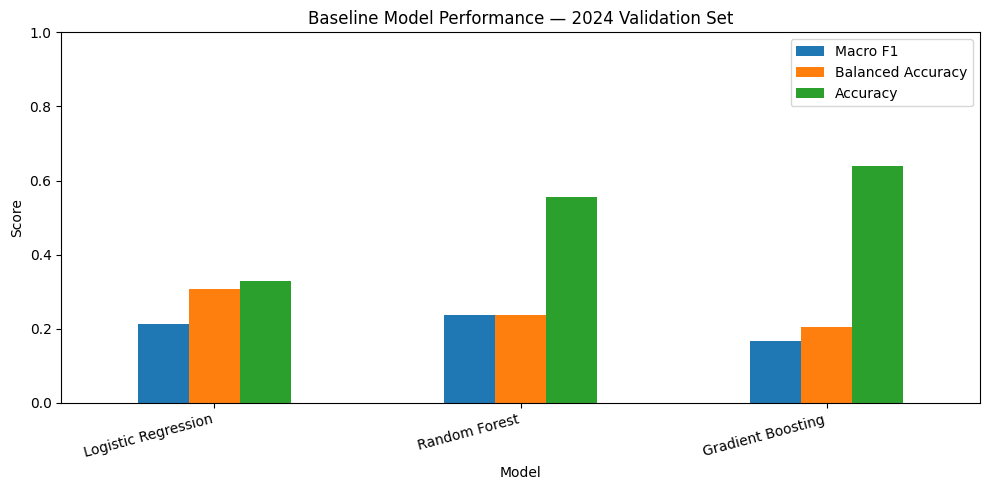

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

baseline_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Macro F1": [0.213827, 0.236822, 0.167948],
    "Balanced Accuracy": [0.307475, 0.236364, 0.205025],
    "Accuracy": [0.328767, 0.556746, 0.640486]
})

display(baseline_results.round(4))

baseline_results.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Baseline Model Performance — 2024 Validation Set")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.legend(loc="best")
plt.tight_layout()
plt.show()

## Step 7 — Investigate Class-Level Errors

In [ ]:
# Find likely model, prediction, and validation variables
keywords = [
    "model", "pred", "y_val", "val_pred",
    "validation", "train_df", "val_df"
]

for name, obj in list(globals().items()):
    if any(word in name.lower() for word in keywords):
        if not name.startswith("_"):
            print(f"{name}: {type(obj).__name__}")

df_model: DataFrame
train_df: DataFrame
val_df: DataFrame
y_val: Series
models: dict
trained_models: dict
validation_predictions: dict
model: Pipeline
predictions: ndarray
y_pred: ndarray
fitted_model: Pipeline
weighted_pred: ndarray


In [ ]:
print("Trained model keys:")
print(list(trained_models.keys()))

print("\nValidation prediction keys:")
print(list(validation_predictions.keys()))

print("\nValidation target shape:")
print(y_val.shape)

Trained model keys:
['Logistic Regression', 'Random Forest', 'Gradient Boosting']

Validation prediction keys:
['Logistic Regression', 'Random Forest', 'Gradient Boosting']

Validation target shape:
(78481,)



CLASSIFICATION REPORT: Logistic Regression
                 precision    recall  f1-score   support

   Fatal_Injury       0.02      0.51      0.03       502
   Minor_Injury       0.25      0.21      0.23     12585
    Not_Injured       0.71      0.36      0.48     50156
Possible_Injury       0.22      0.36      0.27     12919
 Serious_Injury       0.04      0.10      0.06      2319

       accuracy                           0.33     78481
      macro avg       0.25      0.31      0.21     78481
   weighted avg       0.53      0.33      0.39     78481



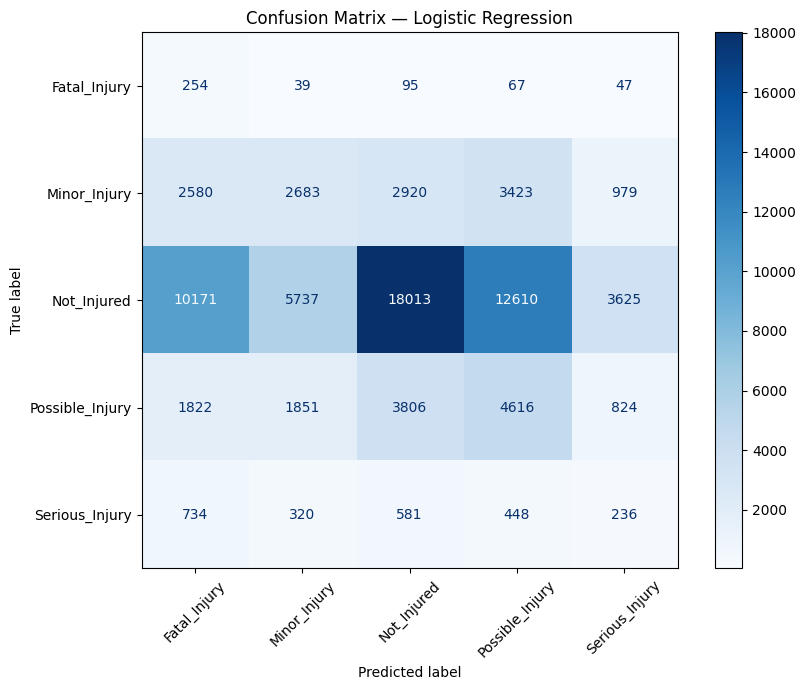


CLASSIFICATION REPORT: Random Forest
                 precision    recall  f1-score   support

   Fatal_Injury       0.04      0.04      0.04       502
   Minor_Injury       0.25      0.17      0.20     12585
    Not_Injured       0.67      0.78      0.72     50156
Possible_Injury       0.22      0.17      0.19     12919
 Serious_Injury       0.05      0.02      0.03      2319

       accuracy                           0.56     78481
      macro avg       0.25      0.24      0.24     78481
   weighted avg       0.51      0.56      0.53     78481



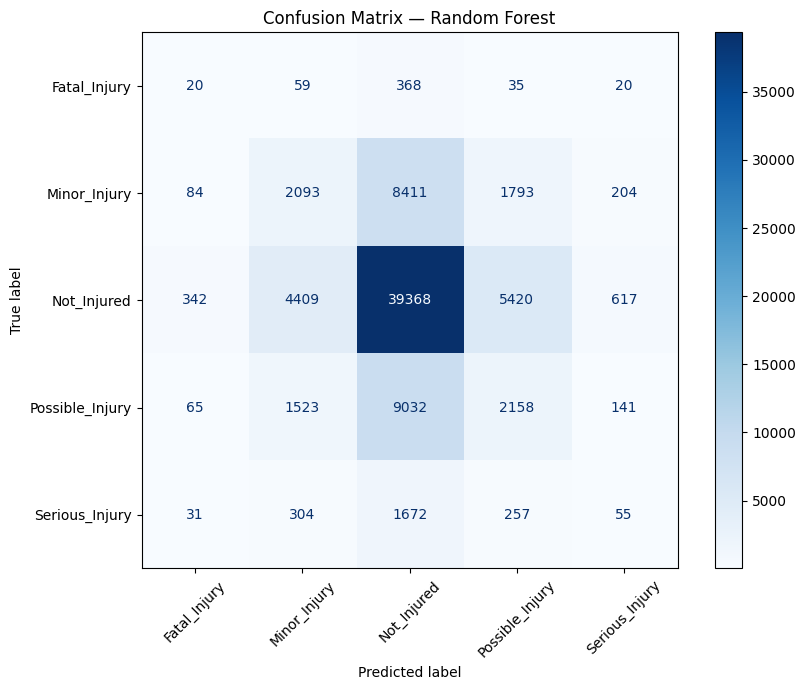


CLASSIFICATION REPORT: Gradient Boosting
                 precision    recall  f1-score   support

   Fatal_Injury       0.00      0.00      0.00       502
   Minor_Injury       0.47      0.02      0.05     12585
    Not_Injured       0.64      0.99      0.78     50156
Possible_Injury       0.33      0.01      0.01     12919
 Serious_Injury       0.00      0.00      0.00      2319

       accuracy                           0.64     78481
      macro avg       0.29      0.21      0.17     78481
   weighted avg       0.54      0.64      0.51     78481



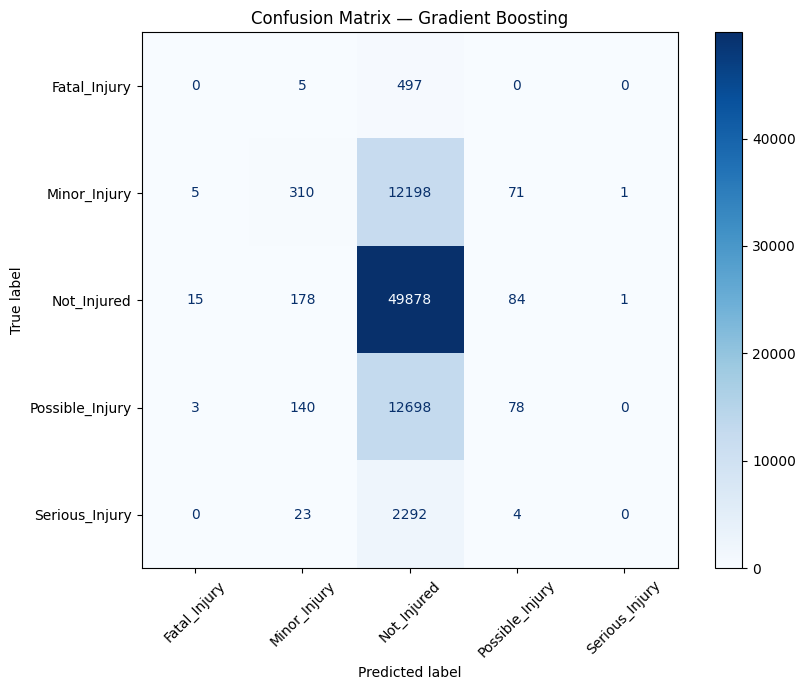

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)

for name, y_pred in validation_predictions.items():
    print("\n" + "=" * 60)
    print(f"CLASSIFICATION REPORT: {name}")
    print("=" * 60)

    print(classification_report(
        y_val,
        y_pred,
        zero_division=0
    ))

    labels = sorted(y_val.unique())

    cm = confusion_matrix(
        y_val,
        y_pred,
        labels=labels
    )

    display_labels = [str(label) for label in labels]

    fig, ax = plt.subplots(figsize=(9, 7))

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=display_labels
    ).plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=45,
        values_format="d"
    )

    ax.set_title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

## Step 8 — Class-Weighting Experiment

In [ ]:
import time
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    accuracy_score,
    classification_report
)

# Reuse the original Logistic Regression preprocessing
original_lr = trained_models["Logistic Regression"]
preprocessor = clone(original_lr.named_steps["preprocessor"])

# Use the same feature columns as the baseline experiment
numeric_features = [
    "Crash_Month", "Crash_DayOfWeek", "Is_Weekend",
    "Crash_Hour", "Latitude", "Longitude"
]
categorical_features = [
    "Time_Period", "City_ID",
    "Light_Cond_ID", "Intrsct_Relat_ID"
]
feature_cols = numeric_features + categorical_features

X_train = train_df[feature_cols]
y_train = train_df["Severity_Target"]

X_val = val_df[feature_cols]
y_val = val_df["Severity_Target"]

# Stronger weights for minority classes
class_weights = {
    "Not_Injured": 1.0,
    "Minor_Injury": 2.0,
    "Possible_Injury": 2.0,
    "Serious_Injury": 4.0,
    "Fatal_Injury": 6.0
}

weighted_lr = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=500,
        class_weight=class_weights,
        solver="lbfgs"
    ))
])

start = time.time()
weighted_lr.fit(X_train, y_train)
weighted_pred = weighted_lr.predict(X_val)
training_seconds = time.time() - start

print("Training time:", round(training_seconds, 2), "seconds")
print("Macro F1:", round(
    f1_score(y_val, weighted_pred, average="macro", zero_division=0), 4
))
print("Balanced accuracy:", round(
    balanced_accuracy_score(y_val, weighted_pred), 4
))
print("Accuracy:", round(
    accuracy_score(y_val, weighted_pred), 4
))

print("\nClassification Report:")
print(classification_report(
    y_val,
    weighted_pred,
    zero_division=0
))

Training time: 18.24 seconds
Macro F1: 0.2016
Balanced accuracy: 0.2179
Accuracy: 0.627

Classification Report:
                 precision    recall  f1-score   support

   Fatal_Injury       0.00      0.00      0.00       502
   Minor_Injury       0.36      0.07      0.12     12585
    Not_Injured       0.65      0.94      0.77     50156
Possible_Injury       0.27      0.08      0.12     12919
 Serious_Injury       0.11      0.00      0.00      2319

       accuracy                           0.63     78481
      macro avg       0.28      0.22      0.20     78481
   weighted avg       0.52      0.63      0.53     78481



## Step 9 — Random Oversampling

In [ ]:
%pip install -q imbalanced-learn

from imblearn.over_sampling import RandomOverSampler

print("RandomOverSampler is ready.")

RandomOverSampler is ready.


In [ ]:
import time
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    accuracy_score,
    classification_report
)
from imblearn.over_sampling import RandomOverSampler

# Use the same training and validation data as the baseline models
X_train = train_df[feature_cols]
y_train = train_df["Severity_Target"]

X_val = val_df[feature_cols]
y_val = val_df["Severity_Target"]

# Fit preprocessing on training data only
oversample_preprocessor = clone(
    trained_models["Logistic Regression"].named_steps["preprocessor"]
)

X_train_transformed = oversample_preprocessor.fit_transform(X_train)
X_val_transformed = oversample_preprocessor.transform(X_val)

# Oversample training data only
sampler = RandomOverSampler(random_state=42)

X_train_resampled, y_train_resampled = sampler.fit_resample(
    X_train_transformed,
    y_train
)

print("Original training class counts:")
print(y_train.value_counts())

print("\nOversampled training class counts:")
print(pd.Series(y_train_resampled).value_counts())

# Train a new Logistic Regression model on the resampled data
oversampled_lr = LogisticRegression(
    max_iter=500,
    solver="lbfgs",
    random_state=42
)

start = time.time()

oversampled_lr.fit(X_train_resampled, y_train_resampled)

oversampled_pred = oversampled_lr.predict(X_val_transformed)

training_seconds = time.time() - start

print("\nTraining time:", round(training_seconds, 2), "seconds")
print("Macro F1:", round(
    f1_score(y_val, oversampled_pred, average="macro", zero_division=0), 4
))
print("Balanced accuracy:", round(
    balanced_accuracy_score(y_val, oversampled_pred), 4
))
print("Accuracy:", round(
    accuracy_score(y_val, oversampled_pred), 4
))

print("\nClassification Report:")
print(classification_report(
    y_val,
    oversampled_pred,
    zero_division=0
))

Original training class counts:
Severity_Target
Not_Injured        172954
Possible_Injury     44784
Minor_Injury        36412
Serious_Injury       7575
Fatal_Injury         1613
Name: count, dtype: int64

Oversampled training class counts:
Severity_Target
Not_Injured        172954
Minor_Injury       172954
Possible_Injury    172954
Serious_Injury     172954
Fatal_Injury       172954
Name: count, dtype: int64

Training time: 55.12 seconds
Macro F1: 0.2138
Balanced accuracy: 0.3074
Accuracy: 0.3283

Classification Report:
                 precision    recall  f1-score   support

   Fatal_Injury       0.02      0.50      0.03       502
   Minor_Injury       0.25      0.22      0.23     12585
    Not_Injured       0.71      0.36      0.48     50156
Possible_Injury       0.22      0.36      0.27     12919
 Serious_Injury       0.04      0.10      0.06      2319

       accuracy                           0.33     78481
      macro avg       0.25      0.31      0.21     78481
   weighted avg 

## Step 10 — Compare all experiments

In [ ]:
import pandas as pd

comparison_df = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Macro F1": 0.213827,
        "Balanced Accuracy": 0.307475,
        "Accuracy": 0.328767
    },
    {
        "Model": "Random Forest",
        "Macro F1": 0.236822,
        "Balanced Accuracy": 0.236364,
        "Accuracy": 0.556746
    },
    {
        "Model": "Gradient Boosting",
        "Macro F1": 0.167948,
        "Balanced Accuracy": 0.205025,
        "Accuracy": 0.640486
    },
    {
        "Model": "Weighted Logistic Regression",
        "Macro F1": 0.2016,
        "Balanced Accuracy": 0.2179,
        "Accuracy": 0.6270
    },
    {
        "Model": "Oversampled Logistic Regression",
        "Macro F1": 0.2138,
        "Balanced Accuracy": 0.3074,
        "Accuracy": 0.3283
    }
])

comparison_df = comparison_df.sort_values(
    by="Macro F1", ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))

print(
    "Best existing experiment by validation Macro F1:",
    comparison_df.iloc[0]["Model"]
)

,Model,Macro F1,Balanced Accuracy,Accuracy
0,Random Forest,0.2368,0.2364,0.5567
1,Logistic Regression,0.2138,0.3075,0.3288
2,Oversampled Logistic Regression,0.2138,0.3074,0.3283
3,Weighted Logistic Regression,0.2016,0.2179,0.6270
4,Gradient Boosting,0.1679,0.2050,0.6405


Best existing experiment by validation Macro F1: Random Forest


## Step 11: Final Model Selection and Justification

In [ ]:
import pandas as pd

# Fallback recovery in case the previous cell was not executed or state was lost
if "comparison_df" not in globals():
    print("Warning: 'comparison_df' not found in memory. Reconstructing metrics table...")
    comparison_df = pd.DataFrame([
        {
            "Model": "Logistic Regression",
            "Macro F1": 0.213827,
            "Balanced Accuracy": 0.307475,
            "Accuracy": 0.328767
        },
        {
            "Model": "Random Forest",
            "Macro F1": 0.236822,
            "Balanced Accuracy": 0.236364,
            "Accuracy": 0.556746
        },
        {
            "Model": "Gradient Boosting",
            "Macro F1": 0.167948,
            "Balanced Accuracy": 0.205025,
            "Accuracy": 0.640486
        },
        {
            "Model": "Weighted Logistic Regression",
            "Macro F1": 0.2016,
            "Balanced Accuracy": 0.2179,
            "Accuracy": 0.6270
        },
        {
            "Model": "Oversampled Logistic Regression",
            "Macro F1": 0.2138,
            "Balanced Accuracy": 0.3074,
            "Accuracy": 0.3283
        }
    ])

best_model_row = comparison_df.loc[
    comparison_df["Macro F1"].idxmax()
]

print("Provisional model:", best_model_row["Model"])
print("Macro F1:", round(best_model_row["Macro F1"], 4))
print("Balanced Accuracy:", round(best_model_row["Balanced Accuracy"], 4))
print("Accuracy:", round(best_model_row["Accuracy"], 4))

Provisional model: Random Forest
Macro F1: 0.2368
Balanced Accuracy: 0.2364
Accuracy: 0.5567
